
# Models 3 and 4 — Linear Regression and Random Forest

### Behavioral Predictors of One-Year Percentage Weight Change · NHANES August 2021–August 2023

**Research Question:** Which behavioral characteristics best predict one-year percentage weight change among U.S. adults who tried to lose weight, beyond demographics and starting BMI?

### Overview

This notebook documents the development, evaluation, and interpretation of ordinary least squares (OLS) Linear Regression and Random Forest models for predicting one-year percentage weight change among adults who reported attempting to lose weight.

Data collection, cleaning, feature engineering, and initial predictor selection were completed as part of the group's earlier work. The present analyses use the shared `nhanes_model_ready.csv` dataset, containing 2,794 participants and 27 predictors (15 covariates and 12 behavioral characteristics).

For each modeling approach, we compare two predictor sets:

- **Covariates only:** 15 demographic, socioeconomic, and baseline body-size predictors.
- **Covariates + behaviors:** The same 15 covariates plus 12 behavioral predictors.

The primary objective is to evaluate whether adding behavioral characteristics improves predictive accuracy beyond demographics and starting BMI. We also examine individual predictor contributions to identify potentially informative characteristics.

**Outcome:** One-year percentage weight change, where negative values indicate weight loss and positive values indicate weight gain.

**Evaluation:** Models are evaluated using cross-validation and a held-out test set. All reported modeling metrics are unweighted.

### Analytical Workflow

Data loading → Predictor definition → Train/test split → Initial model comparison → Random Forest hyperparameter tuning → Repeated cross-validation → Held-out test evaluation → Bootstrap confidence intervals → Model interpretation and limitations.

**Reproducibility:** The analysis uses the group's common 80/20 training/test split (2,235/559 participants). Hyperparameter selection is conducted using training data only, and repeated nested cross-validation evaluates the Random Forest tuning procedure. The held-out test set is reserved for final evaluation.



## 1. Setup and Data Loading

This section imports the Python libraries required for modeling and loads the team's cleaned NHANES dataset (`nhanes_model_ready.csv`), containing 2,794 participants and 33 variables.

Run the notebook from top to bottom. The CSV is expected in a sibling `data/` directory when the notebook is run from `notebooks/`. Adjust `DATA_PATH` if your VS Code working directory differs.

**Missing Data Check:** We examine missing values for four selected predictors: baseline BMI (`bmi_1yr_ago`), income-to-poverty ratio (`income_poverty_ratio`), depressive symptoms (`phq9_score`), and alcohol consumption (`drinks_per_week`). Baseline BMI is included because of its predictive importance, while the latter three have relatively substantial missingness and were identified in the team's earlier preprocessing work.

This check is illustrative rather than exhaustive. Missing values across all included predictors are subsequently handled through median imputation within the modeling pipelines.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RepeatedKFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path('../data/nhanes_model_ready.csv')
if not DATA_PATH.exists():
    alternative = Path('data/nhanes_model_ready.csv')
    if alternative.exists():
        DATA_PATH = alternative

df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
assert df.shape == (2794, 33), 'Check that you loaded the shared model-ready CSV.'
print('Missing values in selected columns:')
display(df[['bmi_1yr_ago', 'income_poverty_ratio', 'phq9_score', 'drinks_per_week']].isna().sum().to_frame('Missing N'))

Dataset shape: (2794, 33)
Missing values in selected columns:


,Missing N
bmi_1yr_ago,11
income_poverty_ratio,325
phq9_score,333
drinks_per_week,346


## 2. Outcome and predictor groups
The outcome is `pct_wt_change`, representing one-year percentage weight change. Using the group's previously defined predictor categories, we compare 15 demographic, socioeconomic, and baseline body-size covariates against an expanded set that includes 12 behavioral predictors. Participant identifiers, survey-design variables, and the secondary weight-loss classification outcome are excluded from the predictor matrix.

In [2]:
# Define columns that are not predictors
exclude_cols = [
    "Respondent sequence number",
    "Full sample 2-year MEC exam weight",
    "Masked variance pseudo-stratum",
    "Masked variance pseudo-PSU",
    "pct_wt_change",
    "lost_5pct"
]

# Define predictors and outcome
feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

X = df[feature_cols].copy()
y = df["pct_wt_change"].copy()

# Verify dimensions
print("Number of participants:", len(df))
print("Number of predictors:", len(feature_cols))
print("Predictor matrix:", X.shape)
print("Outcome:", y.shape)

Number of participants: 2794
Number of predictors: 27
Predictor matrix: (2794, 27)
Outcome: (2794,)


In [3]:
# Define behavioral predictors
behavior_features = [
    "mod_min_wk",
    "vig_min_wk",
    "sedentary_hr_day",
    "phq9_score",
    "drinks_per_week",
    "sleep_hr_avg",
    "main_meal_planner",
    "shares_meal_planning",
    "main_food_shopper",
    "shares_food_shopping",
    "smoking_status_Former",
    "smoking_status_Current"
]

# All other modeling features are covariates
covariate_features = [
    col for col in feature_cols
    if col not in behavior_features
]

# Full predictor set
all_features = covariate_features + behavior_features

# Verify the groups
print("Covariates:", len(covariate_features))
print("Behaviors:", len(behavior_features))
print("Total predictors:", len(all_features))

assert len(covariate_features) == 15
assert len(behavior_features) == 12
assert set(all_features) == set(feature_cols)

Covariates: 15
Behaviors: 12
Total predictors: 27



## 3. Common Train/Test Split

To ensure comparability with the group's other modeling approaches, we reproduce the shared 80/20 training/test split using `random_state=42`.

Participants are stratified according to quantile-based categories of `pct_wt_change` to maintain approximately similar outcome distributions across the two samples.

The training sample (n = 2,235) is used for model development, cross-validation, and hyperparameter tuning. The held-out test sample (n = 559) is reserved for final model evaluation.

This separation helps assess predictive performance on participants whose outcomes were not used during model development.


In [4]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Reproduce teammate's stratification procedure
RANDOM_STATE = 42

strata = pd.qcut(
    df["pct_wt_change"],
    5,
    labels=False,
    duplicates="drop"
)

# Split participant indices
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=strata
)

# Create training and test datasets
X_train = X.loc[idx_train]
X_test = X.loc[idx_test]

y_train = y.loc[idx_train]
y_test = y.loc[idx_test]

# Verify dimensions
print("Training participants:", len(X_train))
print("Test participants:", len(X_test))

print("\nTraining predictors:", X_train.shape)
print("Test predictors:", X_test.shape)

# Verify no overlap
assert set(idx_train).isdisjoint(set(idx_test))

print("\nNo overlap between training and test participants.")

Training participants: 2235
Test participants: 559

Training predictors: (2235, 27)
Test predictors: (559, 27)

No overlap between training and test participants.



## 4. Preprocessing and Initial Model Comparisons

Both Linear Regression and Random Forest use preprocessing pipelines to handle missing predictor values through median imputation. Linear Regression additionally standardizes predictors to facilitate coefficient interpretation, whereas Random Forest does not require scaling.

Preprocessing is fitted separately within each training fold during cross-validation to prevent information from validation participants from influencing model development.

We initially evaluate both models using five-fold cross-validation on the training sample (n = 2,235), comparing:

- **Covariates only:** 15 predictors.
- **Covariates + behaviors:** All 27 predictors.

Model performance is assessed using mean absolute error (MAE), root mean squared error (RMSE), and R². Lower MAE and RMSE and higher R² indicate better predictive performance.

These initial comparisons establish preliminary benchmarks before Random Forest hyperparameter tuning and more extensive repeated cross-validation.


In [5]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

# Use the same five folds for both models
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define preprocessing and regression pipeline
def make_linear_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

# Define predictor sets
linear_feature_sets = {
    "Covariates only": covariate_features,
    "Covariates + behaviors": all_features
}

# Evaluate models
linear_results = []

for name, features in linear_feature_sets.items():

    model = make_linear_model()

    scores = cross_validate(
        model,
        X_train[features],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    linear_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

# Display comparison
linear_comparison = pd.DataFrame(linear_results)

display(linear_comparison.round(3))

,Model,MAE,RMSE,R2
0,Covariates only,5.947,8.256,0.114
1,Covariates + behaviors,5.962,8.224,0.121


In [6]:
from sklearn.ensemble import RandomForestRegressor

# Define Random Forest pipeline
def make_random_forest_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", RandomForestRegressor(
            n_estimators=50,
            max_depth=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1
        ))
    ])

# Evaluate both predictor sets
rf_results = []

for name, features in linear_feature_sets.items():

    model = make_random_forest_model()

    scores = cross_validate(
        model,
        X_train[features],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    rf_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

# Display results
rf_comparison = pd.DataFrame(rf_results)

display(rf_comparison.round(3))

,Model,MAE,RMSE,R2
0,Covariates only,6.049,8.327,0.097
1,Covariates + behaviors,5.986,8.258,0.112




## 5. Random Forest Hyperparameter Tuning

To improve upon the initial Random Forest model, we used `RandomizedSearchCV` to evaluate alternative combinations of four hyperparameters: number of trees (`n_estimators`), maximum tree depth (`max_depth`), minimum leaf size (`min_samples_leaf`), and proportion of predictors considered at each split (`max_features`).

We specified a range of possible values for each hyperparameter, producing 108 possible combinations. Rather than evaluating all 108, `RandomizedSearchCV` randomly selected 12 configurations to test. Each configuration was evaluated using five-fold cross-validation on the training sample (n = 2,235), with root mean squared error (RMSE) as the primary selection criterion.

The search selected 150 trees, a maximum depth of 5, a minimum leaf size of 2, and `max_features=0.75`. The best cross-validated RMSE during tuning was 8.180.

**Evaluation Consideration:** Because we used the same five-fold cross-validation results both to select the best-performing configuration and to report its predictive accuracy, the RMSE of 8.180 may be optimistic. Specifically, the selected configuration may have performed especially well partly because of chance characteristics of those validation samples. As a result, its reported RMSE could underestimate the prediction error we would observe on new participants.

To address this concern, we subsequently used nested cross-validation, which separates hyperparameter selection (inner folds) from performance evaluation (outer folds). This provides a less selection-biased estimate of how well the Random Forest tuning procedure is likely to perform on unseen observations.



In [7]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd

# Random Forest pipeline
rf_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter combinations to explore
param_distributions = {
    "regressor__n_estimators": [50, 100, 150],
    "regressor__max_depth": [5, 10, 15, None],
    "regressor__min_samples_leaf": [2, 5, 10],
    "regressor__max_features": [0.5, 0.75, 1.0]
}

# Randomized search using training data only
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

rf_search.fit(
    X_train[all_features],
    y_train
)

print("\nBest hyperparameters:")
print(rf_search.best_params_)

print("\nBest cross-validated RMSE:")
print(round(-rf_search.best_score_, 3))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best hyperparameters:
{'regressor__n_estimators': 150, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.75, 'regressor__max_depth': 5}

Best cross-validated RMSE:
8.18



## 6. Repeated Cross-Validation for Linear Regression

To assess the stability of Linear Regression performance across different training and validation partitions, we used five-fold cross-validation repeated five times (`RepeatedKFold`), producing 25 validation results.

We evaluated two predictor sets: 15 covariates alone and the same covariates plus 12 behavioral predictors. For each set, the preprocessing and Linear Regression pipeline was fitted separately within each training fold, preventing information leakage.

Performance was summarized using mean MAE, RMSE, and R² across the 25 validation folds.

To assess the incremental predictive value of behaviors, we calculated the difference in R² (`ΔR²`) between the expanded and covariate-only models for each matched fold. We then examined the average improvement, its standard deviation, and the number of folds in which adding behaviors improved R².

This analysis provides a more stable assessment of model performance than relying on a single five-fold partition, although the repeated validation folds are not statistically independent.


In [8]:
from sklearn.model_selection import RepeatedKFold, cross_validate
import pandas as pd
import numpy as np

# Repeated 5-fold cross-validation:
# 5 folds repeated 5 times = 25 validation folds

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# Compare covariates-only vs. covariates + behaviors
linear_repeated_results = {}

for name, features in linear_feature_sets.items():

    scores = cross_validate(
        make_linear_model(),
        X_train[features],
        y_train,
        cv=repeated_cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    linear_repeated_results[name] = scores

# Summarize performance
linear_repeated_summary = pd.DataFrame([
    {
        "Predictors": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    }
    for name, scores in linear_repeated_results.items()
])

display(linear_repeated_summary.round(3))

,Predictors,MAE,RMSE,R2
0,Covariates only,5.945,8.240,0.116
1,Covariates + behaviors,5.957,8.217,0.121


In [9]:
# Compare R² across the same 25 validation folds

r2_covariates = linear_repeated_results[
    "Covariates only"
]["test_R2"]

r2_behaviors = linear_repeated_results[
    "Covariates + behaviors"
]["test_R2"]

# Difference in R² for each matched fold
r2_differences = r2_behaviors - r2_covariates

print("Mean improvement in R²:", round(r2_differences.mean(), 4))

print(
    "Folds where behaviors improved R²:",
    (r2_differences > 0).sum(),
    "out of",
    len(r2_differences)
)

print(
    "Standard deviation of R² improvement:",
    round(r2_differences.std(), 4)
)

Mean improvement in R²: 0.0048
Folds where behaviors improved R²: 18 out of 25
Standard deviation of R² improvement: 0.0105



## 7. Repeated Nested Cross-Validation for Random Forest

To evaluate Random Forest performance while accounting for hyperparameter selection, we used repeated nested cross-validation on the training sample (n = 2,235).

The **outer cross-validation** consisted of five folds repeated five times, producing 25 validation results. Within each outer training fold, an **inner three-fold cross-validation** procedure evaluated 12 randomly selected hyperparameter configurations and selected the configuration with the lowest average RMSE.

The selected configuration was then refitted on the corresponding outer training fold and evaluated on the outer validation fold, whose observations had not been used for hyperparameter selection.

This procedure was performed separately for the covariate-only model (15 predictors) and the expanded model including behavioral characteristics (27 predictors).

Performance was summarized using mean MAE, RMSE, and R² across the 25 outer validation folds. We also calculated the mean change in R² (`ΔR²`), its standard deviation, and the number of folds in which adding behavioral predictors improved performance.

Unlike the initial hyperparameter search, this procedure provides a less selection-biased estimate of predictive performance because model selection and evaluation occur on separate validation data.


In [11]:
# Define inner cross-validation for hyperparameter tuning
inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [12]:
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.base import clone
import pandas as pd
import numpy as np

# Repeated nested CV for both Random Forest feature sets
rf_repeated_results = {}

for name, features in linear_feature_sets.items():

    search = RandomizedSearchCV(
        estimator=clone(rf_tuning_pipeline),
        param_distributions=param_distributions,
        n_iter=12,
        scoring="neg_root_mean_squared_error",
        cv=inner_cv,
        random_state=42,
        n_jobs=1,
        refit=True
    )

    scores = cross_validate(
        search,
        X_train[features],
        y_train,
        cv=repeated_cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    rf_repeated_results[name] = scores

# Summarize results
rf_repeated_summary = pd.DataFrame([
    {
        "Predictors": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    }
    for name, scores in rf_repeated_results.items()
])

display(rf_repeated_summary.round(3))

# Paired fold-level differences
rf_delta_r2 = (
    rf_repeated_results["Covariates + behaviors"]["test_R2"]
    - rf_repeated_results["Covariates only"]["test_R2"]
)

print("\nMean improvement in R²:", round(rf_delta_r2.mean(), 4))
print("Folds improved:", (rf_delta_r2 > 0).sum(), "out of", len(rf_delta_r2))
print("SD of R² improvement:", round(rf_delta_r2.std(), 4))

,Predictors,MAE,RMSE,R2
0,Covariates only,5.945,8.242,0.116
1,Covariates + behaviors,5.936,8.210,0.122



Mean improvement in R²: 0.0067
Folds improved: 18 out of 25
SD of R² improvement: 0.015



## 8. Cross-Validation Comparison

To compare the predictive performance of Linear Regression and Random Forest, we summarize the results from the repeated cross-validation procedures conducted in Sections 6 and 7.

Both models were evaluated using the same 25 outer validation folds (five-fold cross-validation repeated five times), with Random Forest additionally undergoing hyperparameter tuning within each outer training fold.

For each model, we compare the covariate-only predictor set (15 predictors) with the expanded set including 12 behavioral predictors (27 predictors). Performance is assessed using mean absolute error (MAE), root mean squared error (RMSE), and R².

**Key Findings:**

- Adding behavioral predictors modestly improved R² and RMSE for both Linear Regression and Random Forest.
- The expanded Random Forest achieved the highest cross-validated R² (0.122), compared with 0.121 for the expanded Linear Regression model.
- The difference between the two modeling approaches was minimal, suggesting that Random Forest's additional complexity did not produce a substantial improvement in predictive accuracy.
- Overall predictive performance remained modest, indicating that much of the variation in percentage weight change was not captured by the available predictors.

The visualization below compares mean cross-validated R² across the four models. Higher R² values indicate better predictive performance.

These results are based exclusively on the training sample (n = 2,235). Final predictive performance is evaluated separately using the held-out test sample in Section 9.


,Model,Predictors,MAE,RMSE,R2
0,Linear Regression,Covariates only,5.945,8.240,0.116
1,Linear Regression,Covariates + behaviors,5.957,8.217,0.121
2,Random Forest (nested),Covariates only,5.945,8.242,0.116
3,Random Forest (nested),Covariates + behaviors,5.936,8.210,0.122


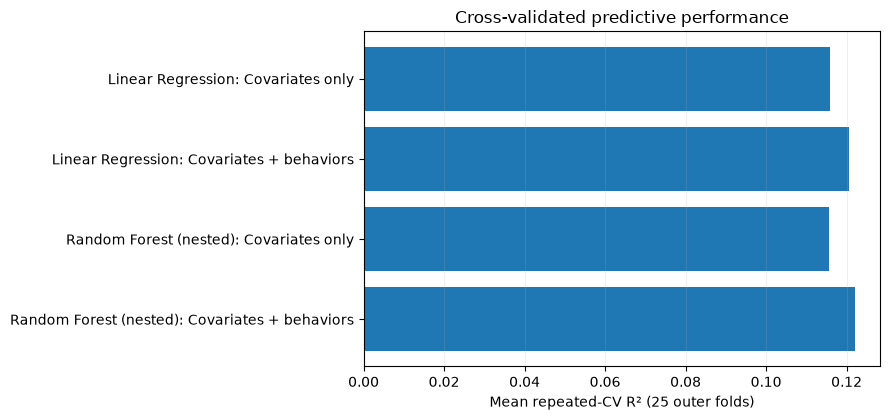

In [13]:
cv_comparison = pd.concat([
    linear_repeated_summary.assign(Model='Linear Regression'),
    rf_repeated_summary.assign(Model='Random Forest (nested)')
], ignore_index=True)[['Model', 'Predictors', 'MAE', 'RMSE', 'R2']]
display(cv_comparison.round(3))

fig, ax = plt.subplots(figsize=(9, 4.3))
labels = [f'{r.Model}: {r.Predictors}' for r in cv_comparison.itertuples()]
ax.barh(labels[::-1], cv_comparison['R2'].to_numpy()[::-1])
ax.set_xlabel('Mean repeated-CV R² (25 outer folds)')
ax.set_title('Cross-validated predictive performance')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()


## 9. Held-Out Test Evaluation

Following model development and cross-validation, we evaluate the finalized Linear Regression and Random Forest models on the shared held-out test sample (n = 559).

Each model is fitted using all 2,235 training participants and evaluated on the same test participants. For Random Forest, the hyperparameters were selected through the randomized search conducted on the full training sample in Section 5. The repeated nested cross-validation procedure in Section 7 was used separately to estimate the predictive performance of the tuning procedure, with hyperparameter selection conducted independently within each outer training fold. This distinction ensures that the final test-set evaluation uses a configuration selected without involving the held-out test participants.

For both modeling approaches, we compare the covariate-only predictor set (15 predictors) with the expanded set including 12 behavioral predictors (27 predictors).

Predictive performance is evaluated using mean absolute error (MAE), root mean squared error (RMSE), and R². These test-set results provide an assessment of model performance on participants who were not used during model fitting or hyperparameter selection.

The test predictions are also saved for subsequent bootstrap analyses of the incremental predictive value of behavioral characteristics.



In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.base import clone
import numpy as np
import pandas as pd

test_results = []
test_predictions = {}

# Final models
final_models = {
    "Linear Regression": make_linear_model(),
    "Random Forest": clone(rf_search.best_estimator_)
}

for model_name, model in final_models.items():
    for feature_set, features in linear_feature_sets.items():

        fitted_model = clone(model)

        # Fit on training participants only
        fitted_model.fit(
            X_train[features],
            y_train
        )

        # Predict held-out test participants
        predictions = fitted_model.predict(
            X_test[features]
        )

        # Save predictions for bootstrap analysis
        test_predictions[(model_name, feature_set)] = predictions

        # Calculate test metrics
        test_results.append({
            "Model": model_name,
            "Predictors": feature_set,
            "Test MAE": mean_absolute_error(
                y_test, predictions
            ),
            "Test RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "Test R2": r2_score(
                y_test, predictions
            )
        })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(3))

,Model,Predictors,Test MAE,Test RMSE,Test R2
0,Linear Regression,Covariates only,6.072,8.765,0.068
1,Linear Regression,Covariates + behaviors,6.031,8.687,0.085
2,Random Forest,Covariates only,6.077,8.744,0.073
3,Random Forest,Covariates + behaviors,6.051,8.707,0.081




## 10. Bootstrap Confidence Intervals for Behavioral Added Value

To assess uncertainty in the incremental predictive value of behavioral characteristics, we calculated the difference in held-out test R² (`ΔR²`) between the expanded model (27 predictors) and the covariate-only model (15 predictors).

For both Linear Regression and Random Forest, we used a paired bootstrap procedure with 2,000 resamples of the 559 test participants, sampled with replacement. For each resample, we calculated R² for both predictor sets using their previously saved predictions and recorded the difference.

The 2.5th and 97.5th percentiles of the resulting bootstrap distribution were used to construct a 95% confidence interval for `ΔR²`.

A positive `ΔR²` indicates improved predictive performance after adding behavioral predictors. If the confidence interval includes zero, the observed improvement cannot be confidently distinguished from no improvement under this bootstrap procedure.

### Limitations

**Uncertainty from Model Training:** The bootstrap procedure resamples test participants while keeping the previously fitted models and their predictions fixed. It therefore estimates uncertainty in the observed improvement in test-set R², conditional on the trained models. It does not account for additional variability that might arise if the models were retrained on different training samples, potentially producing different regression coefficients, decision-tree structures, and predictions.

**NHANES Complex Sampling Design:** The bootstrap procedure treats individual test participants as independent observations and does not incorporate NHANES survey weights, sampling strata, or primary sampling units (PSUs). Because NHANES uses a complex probability-sampling design, these features can affect both population-level estimates and their uncertainty. Consequently, the confidence intervals should be interpreted as unweighted, participant-level bootstrap estimates rather than fully survey-design-adjusted estimates representative of the U.S. adult population.

These limitations do not invalidate the analysis, but they restrict the conclusions that can be drawn from the resulting confidence intervals.



In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

rng = np.random.default_rng(42)

n_bootstrap = 2000
y_true = np.asarray(y_test)

bootstrap_results = []

for model_name in ["Linear Regression", "Random Forest"]:

    pred_cov = test_predictions[
        (model_name, "Covariates only")
    ]

    pred_full = test_predictions[
        (model_name, "Covariates + behaviors")
    ]

    # Observed improvement in test R²
    observed_delta = (
        r2_score(y_true, pred_full)
        - r2_score(y_true, pred_cov)
    )

    bootstrap_deltas = []

    for _ in range(n_bootstrap):

        # Resample participants with replacement
        indices = rng.choice(
            len(y_true),
            size=len(y_true),
            replace=True
        )

        y_boot = y_true[indices]

        delta = (
            r2_score(y_boot, pred_full[indices])
            - r2_score(y_boot, pred_cov[indices])
        )

        bootstrap_deltas.append(delta)

    # Percentile-based 95% confidence interval
    ci_lower, ci_upper = np.percentile(
        bootstrap_deltas,
        [2.5, 97.5]
    )

    bootstrap_results.append({
        "Model": model_name,
        "Test Delta R2": observed_delta,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper
    })

bootstrap_summary = pd.DataFrame(bootstrap_results)

display(bootstrap_summary.round(3))

,Model,Test Delta R2,95% CI Lower,95% CI Upper
0,Linear Regression,0.017,-0.003,0.037
1,Random Forest,0.008,-0.008,0.027



## 11. Interpretation: Standardized Linear Regression Coefficients

To examine which individual characteristics are associated with one-year percentage weight change, we fitted the Linear Regression model using all 27 predictors and the complete training sample (n = 2,235).

Because predictors were standardized within the modeling pipeline, each regression coefficient represents the expected difference in percentage weight change associated with a one-standard-deviation increase in that predictor, holding the other predictors constant.

Negative coefficients indicate associations with more negative percentage weight change (greater weight loss), whereas positive coefficients indicate associations with less weight loss or greater weight gain.

We ranked predictors by the absolute magnitude of their standardized coefficients to identify the largest estimated adjusted associations. Baseline BMI (`bmi_1yr_ago`) was excluded from the visualization, but retained in the fitted model, because its substantially larger coefficient would make the other associations difficult to distinguish graphically.

**Interpretation Considerations:**

- Coefficients represent adjusted associations rather than causal effects.
- Standardized coefficients for binary indicators represent one-standard-deviation changes, not the full difference between categories.
- Larger coefficient magnitudes do not necessarily indicate greater out-of-sample predictive importance.
- Coefficients were estimated from a single model fitted to the full training sample. Their stability across different training samples was not evaluated.

These analyses are exploratory and complement the model-performance comparisons by examining the direction and magnitude of individual predictor associations.


In [16]:
# Fit Linear Regression on the full training sample
linear_final = make_linear_model()

linear_final.fit(
    X_train[all_features],
    y_train
)

# Extract standardized regression coefficients
coefficients = linear_final.named_steps[
    "regressor"
].coef_

# Create coefficient table
linear_coef_df = pd.DataFrame({
    "Feature": all_features,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
linear_coef_df["Abs_Coefficient"] = (
    linear_coef_df["Coefficient"].abs()
)

linear_coef_df = linear_coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the 15 largest coefficients
display(
    linear_coef_df[
        ["Feature", "Coefficient"]
    ].head(15).round(3)
)

,Feature,Coefficient
7,bmi_1yr_ago,-3.172
21,main_meal_planner,-0.699
0,age,-0.557
4,household_size,0.526
2,education,-0.520
26,smoking_status_Current,-0.514
6,veteran,-0.402
16,vig_min_wk,-0.387
11,race_eth_NH Asian,-0.365
9,race_eth_Other Hispanic,-0.359


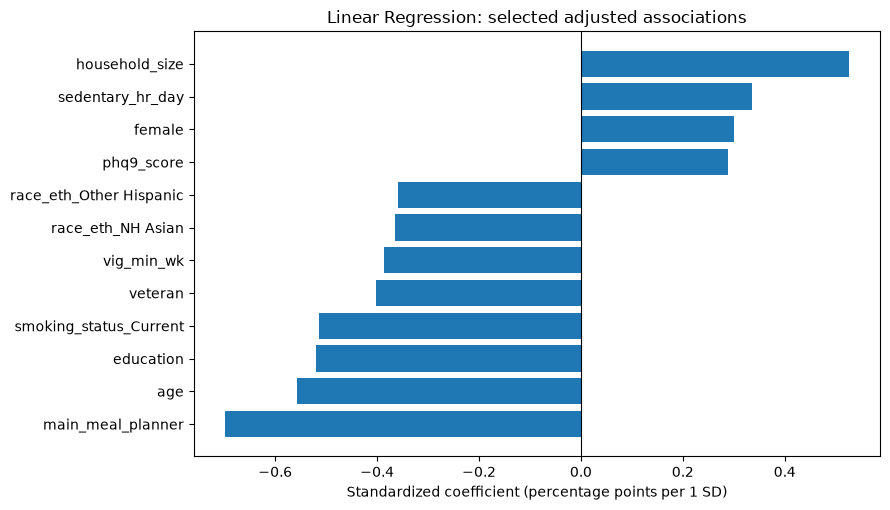

Baseline BMI coefficient: -3.172


In [17]:
plot_coef = linear_coef_df[linear_coef_df['Feature'] != 'bmi_1yr_ago'].head(12).sort_values('Coefficient')
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(plot_coef['Feature'], plot_coef['Coefficient'])
ax.axvline(0, color='black', linewidth=.8)
ax.set_xlabel('Standardized coefficient (percentage points per 1 SD)')
ax.set_title('Linear Regression: selected adjusted associations')
plt.tight_layout()
plt.show()
print('Baseline BMI coefficient:', round(float(linear_coef_df.loc[linear_coef_df.Feature == 'bmi_1yr_ago', 'Coefficient'].iloc[0]), 3))


### Additional Analysis: Interpretation of Binary Predictors

Because our Linear Regression pipeline standardizes all predictors, including binary indicators, their coefficients do not directly represent the difference between categories 1 and 0.

To facilitate interpretation, we identified all 16 binary predictors and converted their standardized coefficients back to the original 0/1 scale using the standard deviations calculated during model fitting. This conversion does not change the fitted model or its predictions.

The resulting coefficients represent adjusted differences in predicted percentage weight change between participants coded 1 and those coded 0, holding the other predictors constant.

Among the behavioral indicators, main meal planning (−1.567 percentage points) and current smoking (−1.632 percentage points) showed the largest negative adjusted differences, indicating associations with greater predicted weight loss for the indicated categories.

For dummy-coded categorical predictors, such as smoking status and race/ethnicity, comparisons are made relative to the omitted reference category rather than all participants outside the indicated category.

**Interpretation Considerations:** These results describe adjusted associations, not causal effects. The analysis is exploratory, and coefficient confidence intervals and stability were not evaluated. Original category coding and reference groups should be verified before drawing substantive conclusions.



In [21]:
# Identify binary predictors and convert standardized coefficients
# into adjusted differences between categories 1 and 0

# Step 1: Identify predictors containing only 0 and 1
binary_features = [
    col for col in all_features
    if set(X_train[col].dropna().unique()).issubset({0, 1})
    and X_train[col].dropna().nunique() == 2
]

# Step 2: Retrieve the fitted scaler and regression coefficients
scaler = linear_final.named_steps["scaler"]
coefs = linear_final.named_steps["regressor"].coef_

# Step 3: Convert coefficients to the original binary scale
binary_results = pd.DataFrame([
    {
        "Feature": feature,
        "Standardized coefficient": (
            coefs[all_features.index(feature)]
        ),
        "Adjusted difference (1 vs 0)": (
            coefs[all_features.index(feature)]
            / scaler.scale_[all_features.index(feature)]
        )
    }
    for feature in binary_features
])

# Step 4: Display the results
print("Number of binary predictors:", len(binary_features))

display(binary_results.round(3))


Number of binary predictors: 16


,Feature,Standardized coefficient,Adjusted difference (1 vs 0)
0,female,0.301,0.618
1,us_born,-0.023,-0.056
2,veteran,-0.402,-1.466
3,race_eth_Mexican American,0.119,0.452
4,race_eth_Other Hispanic,-0.359,-1.118
5,race_eth_NH Black,0.238,0.718
6,race_eth_NH Asian,-0.365,-1.759
7,race_eth_Other/Multiracial,-0.139,-0.582
8,marital_Widowed/divorced/separated,0.251,0.588
9,marital_Never married,0.155,0.393



## 12. Interpretation: Random Forest Permutation Importance

To examine which individual predictors contribute most to Random Forest's predictive performance, we calculated permutation importance using the tuned model with all 27 predictors.

We created a separate 80/20 fitting/validation split within the original training sample (n = 2,235), keeping the final held-out test sample separate. The tuned Random Forest configuration was fitted on the smaller fitting sample and evaluated on the validation subset.

Permutation importance was calculated by randomly shuffling one predictor at a time while leaving the remaining predictors unchanged. We then measured how much validation RMSE increased relative to the model's original predictions. Each predictor was shuffled 10 times, and the mean increase in RMSE was used as its importance score.

Higher positive importance values indicate that disrupting a predictor's information reduces predictive accuracy, suggesting that the fitted model relies more heavily on that predictor. Unlike Linear Regression coefficients, permutation importance does not indicate whether a predictor is associated with greater weight loss or weight gain.

**Interpretation Considerations:**

- Permutation importance measures predictive reliance rather than causal influence.
- Results are exploratory because importance was calculated using one training-only validation split.
- Correlations among predictors can affect importance estimates because related variables may provide overlapping predictive information.
- The standard deviation across the 10 permutations reflects variation across random shuffles, not uncertainty across different participant samples.

This analysis complements the Linear Regression coefficient analysis by examining which characteristics are most important to Random Forest's predictions.


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
import pandas as pd

# Create a validation split within the training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train[all_features],
    y_train,
    test_size=0.20,
    random_state=42
)

# Fit the tuned Random Forest using the selected settings
rf_importance_model = clone(rf_search.best_estimator_)

rf_importance_model.fit(X_fit, y_fit)

# Calculate permutation importance using RMSE
importance = permutation_importance(
    rf_importance_model,
    X_val,
    y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": importance.importances_mean,
    "SD": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(3))

,Feature,Importance,SD
7,bmi_1yr_ago,1.116,0.133
0,age,0.092,0.033
15,mod_min_wk,0.037,0.016
4,household_size,0.037,0.006
18,phq9_score,0.023,0.011
3,income_poverty_ratio,0.021,0.026
2,education,0.014,0.007
16,vig_min_wk,0.011,0.019
8,race_eth_Mexican American,0.011,0.006
9,race_eth_Other Hispanic,0.006,0.003


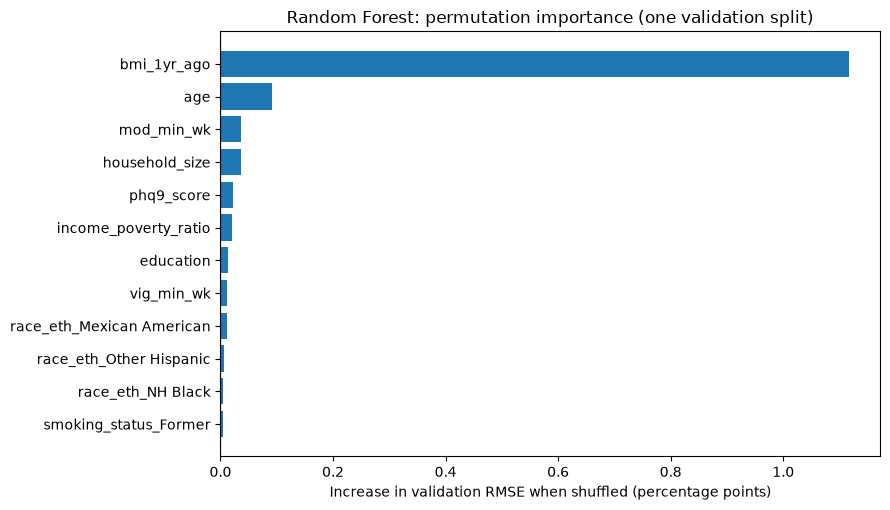

In [23]:
top_imp = importance_df.head(12).sort_values('Importance')
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top_imp['Feature'], top_imp['Importance'])
ax.axvline(0, color='black', linewidth=.8)
ax.set_xlabel('Increase in validation RMSE when shuffled (percentage points)')
ax.set_title('Random Forest: permutation importance (one validation split)')
plt.tight_layout()
plt.show()


## 13. Conclusions and Limitations

### Summary of Findings

This notebook evaluated ordinary Linear Regression and Random Forest models for predicting one-year percentage weight change among U.S. adults who reported attempting to lose weight. The primary objective was to determine whether adding behavioral characteristics improved predictive accuracy beyond demographic, socioeconomic, and baseline BMI covariates.

**Overall Predictive Performance:** Both models demonstrated modest predictive performance. On the held-out test sample (n = 559), Linear Regression with all 27 predictors achieved an R² of 0.085 and RMSE of 8.687, while the expanded Random Forest achieved an R² of 0.081 and RMSE of 8.707. The differences between models were small, suggesting that Random Forest's additional complexity did not provide a substantial predictive advantage.

**Incremental Value of Behavioral Predictors:** Adding the 12 behavioral predictors improved test R² by 0.017 for Linear Regression and 0.008 for Random Forest. However, the corresponding 95% bootstrap confidence intervals included zero (Linear Regression: [−0.003, 0.037]; Random Forest: [−0.008, 0.027]). Thus, although behavioral predictors produced small numerical improvements, their incremental predictive value remains uncertain.

**Individual Predictor Findings:** Baseline BMI (`bmi_1yr_ago`) had the largest standardized Linear Regression coefficient and the highest Random Forest permutation importance.

Among the behavioral characteristics, main meal planning and vigorous physical activity showed negative adjusted associations with percentage weight change in Linear Regression, while sedentary time and depressive symptoms showed positive associations. The adjusted difference for main meal planning was approximately −1.57 percentage points between categories 1 and 0, assuming the expected variable coding.

In Random Forest, moderate physical activity and depressive symptoms were among the more informative behavioral predictors, although their permutation-importance values were relatively small. These results highlight the distinction between adjusted associations and contributions to predictive accuracy.

### Methodological Limitations

**1. Unweighted Analysis:** Models were trained and evaluated without incorporating NHANES survey weights, sampling strata, or primary sampling units (PSUs). Consequently, the reported performance estimates describe the analytic sample and should not automatically be interpreted as nationally representative.

**2. Retrospective Measurement:** Percentage weight change was calculated using current weight and recalled weight from one year earlier. Behavioral characteristics were measured at the time of the NHANES interview and may not reflect behaviors throughout the preceding year. The analyses therefore identify associations rather than causal relationships or prospective predictions.

**3. Shared Measurement Between Baseline BMI and Weight Change:** Estimated baseline BMI and percentage weight change both incorporate reported weight from one year earlier. This shared measurement may contribute to baseline BMI's prominence in the models and complicate interpretation of its predictive importance.

**4. Preprocessing Differences:** Our modeling pipelines used median imputation for missing predictor values. Unlike the group's penalized regression approach, we did not include separate missingness indicators for income-to-poverty ratio, depressive symptoms, or alcohol consumption. These differences may affect comparisons across modeling approaches.

**5. Stability of Individual Predictor Findings:** Although repeated cross-validation was used to assess overall model performance, we did not examine whether individual predictors consistently showed similar coefficients or importance rankings across different samples. Linear Regression coefficients were obtained from one model fitted to the full training sample, while Random Forest permutation importance was calculated using one validation split. Consequently, the individual predictor findings should be considered exploratory until their stability across alternative samples is evaluated.

**6. Bootstrap Uncertainty:** The bootstrap confidence intervals were calculated by resampling individual test participants while keeping the fitted models fixed. They do not incorporate uncertainty from retraining the models or the complex NHANES sampling design.

### Conclusions and Next Steps

Overall, behavioral characteristics provided modest and uncertain additional predictive information beyond demographics and baseline BMI. Neither modeling approach achieved high predictive accuracy, and the greater flexibility of Random Forest did not produce a meaningful advantage over ordinary Linear Regression.

Future analyses could examine survey-weighted evaluation, alternative definitions of weight-related outcomes, sensitivity analyses excluding baseline BMI, and additional behavioral predictors. More extensive assessments of coefficient stability and feature importance could also help determine whether the individual predictor findings are reproducible.

**Reproducibility Note:** This notebook preserves the initial model comparisons and final repeated/nested cross-validation procedures. The held-out test set was reserved for final evaluation and should not be repeatedly used to guide further model selection.
